# Customer Churn Analysis & Retention Strategy
**Python | SQL | Power BI** - why do telecom customers leave, who is likely to leave next, and what should we do about it?

**Business questions**
1. How big is the churn problem (rate and revenue lost)?
2. What drives churn - contract, price, service quality, payment method, tenure?
3. Can we predict which active customers are about to leave?
4. Whom should we contact, given a limited retention budget? What is the expected return?

> Data note: the dataset is **synthetic** (generated by `src/generate_data.py` with realistic churn drivers and deliberate data-quality problems), so findings demonstrate the method, not a real company.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings, os, json
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, confusion_matrix, classification_report, f1_score
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight":"bold","axes.spines.top":False,"axes.spines.right":False})
DATA, IMG, PBI = "../data", "../images", "../powerbi/model_data"
for d in (IMG,PBI): os.makedirs(d, exist_ok=True)
SEED = 42
def save(n): plt.savefig(f"{IMG}/{n}.png", dpi=130, bbox_inches="tight")
print("ready")

ready


## 1. Load raw data and profile it
Always inspect before cleaning: shape, types, missing values, duplicates, impossible values.

In [2]:
raw = pd.read_csv(f"{DATA}/telecom_churn_raw.csv")
print(raw.shape); raw.head()

(7260, 26)


,customer_id,signup_date,gender,senior_citizen,partner,dependents,region,city,tenure_months,contract,payment_method,paperless_billing,phone_service,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,monthly_charges,total_charges,avg_monthly_data_gb,support_tickets_6m,late_payments_12m,churn
0,CUST100946,2021-10-11,Female,0,Yes,No,South,Chennai,60,One year,Credit card,Yes,Yes,No internet,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,263.0,15203.32,0.0,0,2,No
1,CUST100564,2021-02-02,Female,0,No,No,East,Patna,68,Two year,Credit card,Yes,Yes,No internet,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,272.0,18329.00,0.0,0,1,No
2,CUST105551,2023-07-25,Male,0,Yes,No,East,Bhubaneswar,38,Month-to-month,Electronic check,Yes,Yes,DSL,Yes,No,No,No,Yes,No,648.0,24282.71,61.2,1,2,Yes
3,CUST104590,2023-04-08,Female,0,No,No,West,Ahmedabad,42,Two year,Bank transfer,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,Yes,980.0,41099.47,72.4,0,0,Yes
4,CUST101857,2021-01-01,Female,0,No,No,East,Patna,69,Two year,Mailed check,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,960.0,65225.53,133.4,2,0,No


In [3]:
profile = pd.DataFrame({"dtype":raw.dtypes.astype(str), "missing":raw.isna().sum(), "unique":raw.nunique()})
issues = {
 "Duplicate customer_id rows": int(raw.duplicated("customer_id").sum()),
 "Negative monthly_charges": int((raw.monthly_charges<0).sum()),
 "Contract spelling variants": int(raw.contract.nunique()-3),
 "payment_method with stray spaces": int((raw.payment_method!=raw.payment_method.str.strip()).sum()),
}
print(issues); profile[profile.missing>0]

{'Duplicate customer_id rows': 60, 'Negative monthly_charges': 40, 'Contract spelling variants': 3, 'payment_method with stray spaces': 145}


,dtype,missing,unique
gender,str,109,2
total_charges,float64,145,7054


## 2. Data cleaning (every step is logged)
| Problem | Fix | Why |
|---|---|---|
| Duplicate `customer_id` | keep first | one row per customer is the grain of the analysis |
| Contract in mixed case / payment with spaces | strip + standardise | otherwise one category counts as two |
| Negative `monthly_charges` | take absolute value | a sign-entry error (bills cannot be negative) |
| Missing `total_charges` | `monthly_charges x tenure_months` | consistent with how the column is built; keeps the row |
| Missing `gender` | label `Unknown` | not a model driver; do not delete customers |

In [4]:
df = raw.copy(); log=[("Rows in raw file", len(df))]
n=len(df); df = df.drop_duplicates("customer_id", keep="first"); log.append(("Duplicate customers removed", n-len(df)))
df["contract"] = df.contract.str.strip().str.capitalize().replace({"Month-to-month":"Month-to-month","One year":"One year","Two year":"Two year"})
df["payment_method"] = df.payment_method.str.strip()
neg = (df.monthly_charges<0); df.loc[neg,"monthly_charges"] = df.loc[neg,"monthly_charges"].abs(); log.append(("Negative monthly_charges fixed", int(neg.sum())))
m = df.total_charges.isna(); df.loc[m,"total_charges"] = (df.monthly_charges*df.tenure_months).round(2)[m]; log.append(("Missing total_charges imputed", int(m.sum())))
g = df.gender.isna(); df["gender"] = df.gender.fillna("Unknown"); log.append(("Missing gender labelled Unknown", int(g.sum())))
df["signup_date"] = pd.to_datetime(df.signup_date); df["churn_flag"] = (df.churn=="Yes").astype(int)
log.append(("Rows in clean file", len(df)))
assert df.customer_id.is_unique and (df.monthly_charges>0).all() and df.isna().sum().sum()==0
pd.DataFrame(log, columns=["step","rows"]).to_csv(f"{DATA}/cleaning_log.csv", index=False); df.drop(columns="churn_flag").to_csv(f"{DATA}/telecom_churn_clean.csv", index=False)
pd.DataFrame(log, columns=["step","rows"])

,step,rows
0,Rows in raw file,7260
1,Duplicate customers removed,60
2,Negative monthly_charges fixed,40
3,Missing total_charges imputed,144
4,Missing gender labelled Unknown,108
5,Rows in clean file,7200


## 3. How big is the problem?

In [5]:
rate = df.churn_flag.mean(); lost_mrr = df.loc[df.churn_flag==1,"monthly_charges"].sum(); tot_mrr = df.monthly_charges.sum()
print(f"Customers: {len(df):,} | churned: {df.churn_flag.sum():,} ({rate:.1%})")
print(f"Monthly revenue of churned customers: INR {lost_mrr:,.0f} = {lost_mrr/tot_mrr:.1%} of all monthly revenue (annualised INR {lost_mrr*12/1e6:,.1f} M)")
print(f"Average tenure - churned {df[df.churn_flag==1].tenure_months.mean():.1f} vs stayed {df[df.churn_flag==0].tenure_months.mean():.1f} months")

Customers: 7,200 | churned: 1,741 (24.2%)
Monthly revenue of churned customers: INR 1,360,021 = 27.3% of all monthly revenue (annualised INR 16.3 M)
Average tenure - churned 27.0 vs stayed 39.2 months


## 4. What drives churn? (exploratory analysis)
For each categorical driver we compare churn rates, then test whether the difference is **statistically significant** (chi-square test of independence; p < 0.05 means the factor and churn are unlikely to be unrelated).

In [6]:
cats = ["contract","internet_service","payment_method","tech_support","online_security","paperless_billing","senior_citizen","partner","dependents","region","gender"]
rows=[]
for c in cats:
    dd = df[df.gender!="Unknown"] if c=="gender" else df     # exclude the imputed 'Unknown' label from the gender test
    ct = pd.crosstab(dd[c], dd.churn_flag); chi,p,_,_ = stats.chi2_contingency(ct)
    r = dd.groupby(c).churn_flag.mean(); rows.append((c, r.max()-r.min(), r.idxmax(), r.max(), r.idxmin(), r.min(), p, np.sqrt(chi/ct.values.sum())))
drivers = pd.DataFrame(rows, columns=["factor","gap","highest_group","highest_rate","lowest_group","lowest_rate","p_value","cramers_v"]).sort_values("gap", ascending=False)
drivers.assign(significant=lambda d: d.p_value<.05).round(3)

,factor,gap,highest_group,highest_rate,lowest_group,lowest_rate,p_value,cramers_v,significant
0,contract,0.333,Month-to-month,0.409,Two year,0.076,0.000,0.349,True
1,internet_service,0.228,Fiber optic,0.343,No internet,0.115,0.000,0.219,True
3,tech_support,0.190,No,0.306,No internet service,0.115,0.000,0.178,True
4,online_security,0.167,No,0.283,No internet service,0.115,0.000,0.160,True
2,payment_method,0.080,Electronic check,0.292,Credit card,0.212,0.000,0.083,True
8,dependents,0.066,No,0.254,Yes,0.188,0.000,0.059,True
5,paperless_billing,0.042,Yes,0.259,No,0.217,0.000,0.048,True
9,region,0.035,North,0.263,South,0.228,0.086,0.030,False
7,partner,0.028,No,0.255,Yes,0.227,0.006,0.033,True
10,gender,0.026,Female,0.253,Male,0.228,0.012,0.030,True


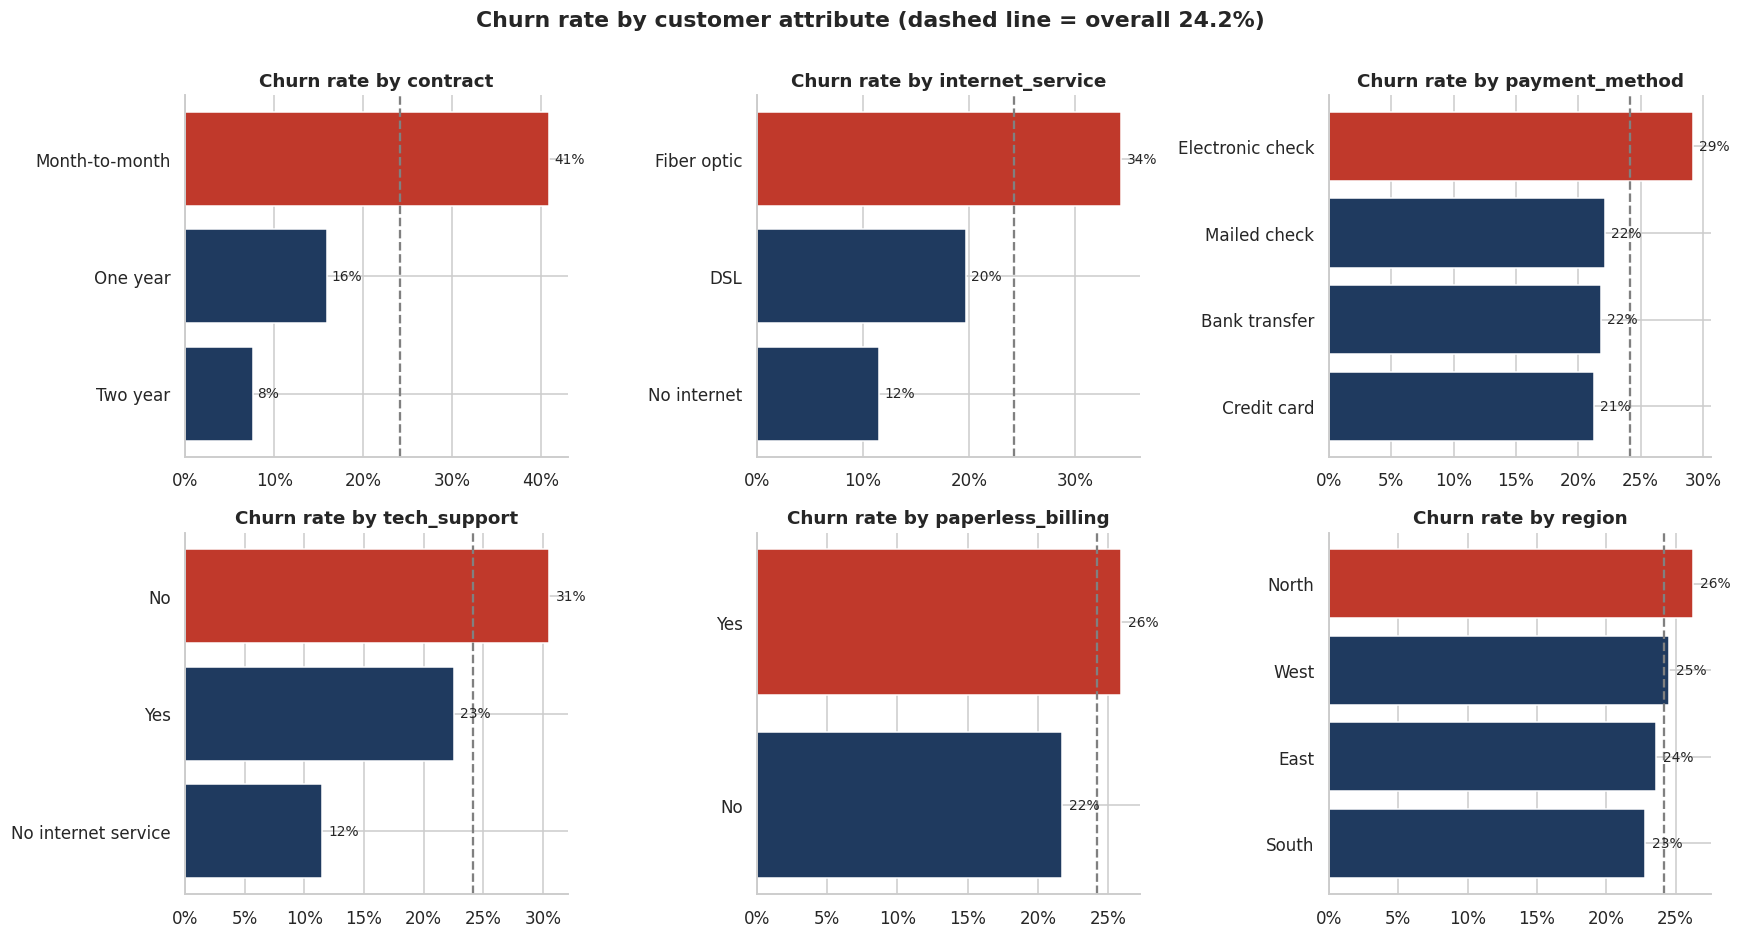

In [7]:
fig, ax = plt.subplots(2,3, figsize=(16,8.5))
for a,c in zip(ax.ravel(), ["contract","internet_service","payment_method","tech_support","paperless_billing","region"]):
    r = df.groupby(c).churn_flag.mean().sort_values(); a.barh(r.index.astype(str), r.values, color=["#C0392B" if v==r.max() else "#1F3A5F" for v in r.values])
    a.axvline(rate, color="grey", ls="--"); a.set_title(f"Churn rate by {c}"); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"{v:.0%}"))
    for i,v in enumerate(r.values): a.text(v+.005, i, f"{v:.0%}", va="center", fontsize=9)
plt.suptitle(f"Churn rate by customer attribute (dashed line = overall {rate:.1%})", fontweight="bold", y=1.0); plt.tight_layout(); save("01_churn_by_category"); plt.show()

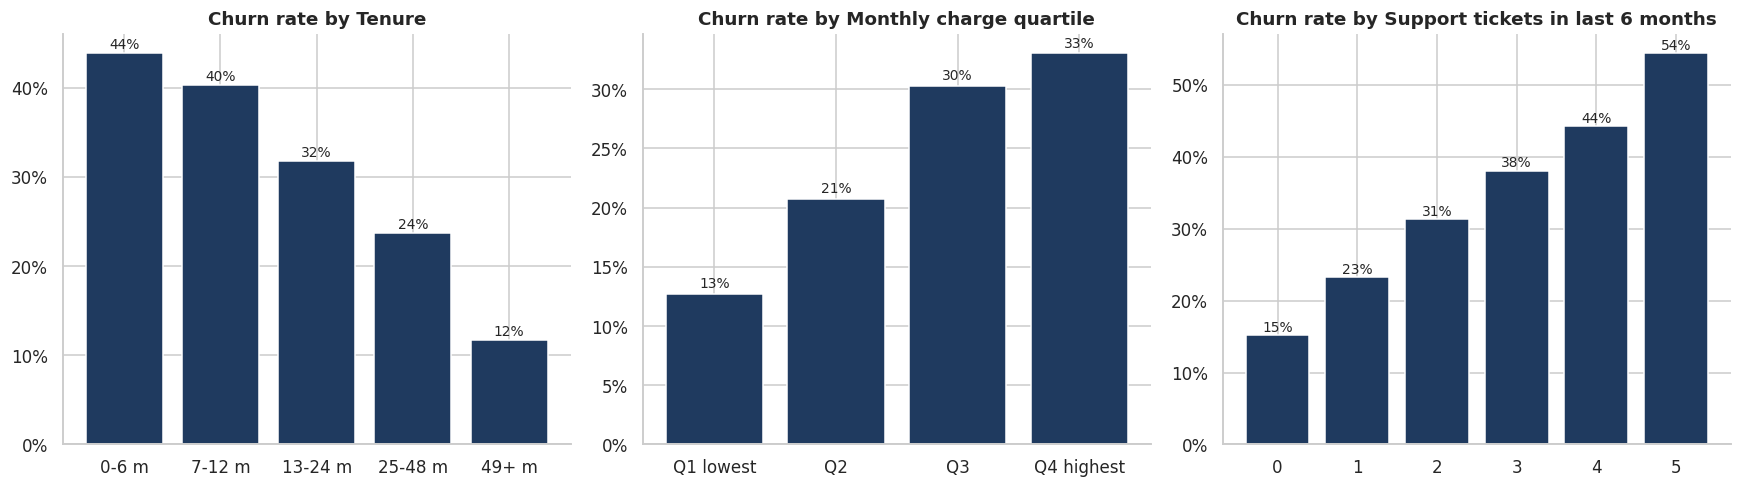

In [8]:
df["tenure_band"] = pd.cut(df.tenure_months, [-1,6,12,24,48,100], labels=["0-6 m","7-12 m","13-24 m","25-48 m","49+ m"])
df["charge_band"] = pd.qcut(df.monthly_charges, 4, labels=["Q1 lowest","Q2","Q3","Q4 highest"])
fig, ax = plt.subplots(1,3, figsize=(16,4.6))
for a,c,t in zip(ax,["tenure_band","charge_band","support_tickets_6m"],["Tenure","Monthly charge quartile","Support tickets in last 6 months"]):
    d = df.assign(**{c: df[c].clip(upper=5) if c=="support_tickets_6m" else df[c]}).groupby(c, observed=True).churn_flag.agg(["mean","size"])
    a.bar(d.index.astype(str), d["mean"], color="#1F3A5F"); a.set_title(f"Churn rate by {t}"); a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"{v:.0%}"))
    for i,(m_,n_) in enumerate(zip(d["mean"],d["size"])): a.text(i, m_+.005, f"{m_:.0%}", ha="center", fontsize=9)
plt.tight_layout(); save("02_churn_by_tenure_charge_tickets"); plt.show()

Month-to-month + Fiber customers: 1,322 (18% of base) but 43% of all churners; churn rate 56%


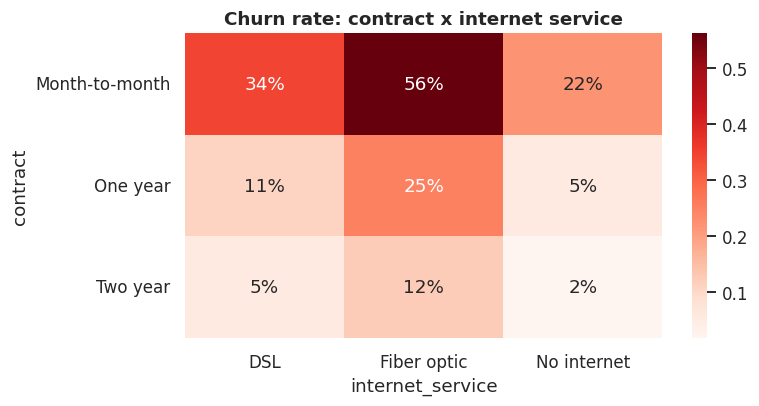

In [9]:
# Two-factor view: the highest-risk profile
pv = df.pivot_table(index="contract", columns="internet_service", values="churn_flag", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7,3.6)); sns.heatmap(pv, annot=True, fmt=".0%", cmap="Reds", ax=ax); ax.set_title("Churn rate: contract x internet service"); save("03_contract_internet_heatmap"); plt.show()
hi = df[(df.contract=="Month-to-month")&(df.internet_service=="Fiber optic")]
print(f"Month-to-month + Fiber customers: {len(hi):,} ({len(hi)/len(df):.0%} of base) but {hi.churn_flag.sum()/df.churn_flag.sum():.0%} of all churners; churn rate {hi.churn_flag.mean():.0%}")

## 5. Feature engineering
Extra features that capture behaviour a model cannot easily infer itself: number of add-on services, price per service, ticket intensity, a tenure-adjusted charge, etc. `total_charges` is dropped from the model because it is almost `monthly_charges x tenure` (multicollinearity).

In [10]:
X = df.drop(columns=["customer_id","signup_date","churn","churn_flag","total_charges","tenure_band","charge_band","city"]).copy()
addons = ["online_security","online_backup","device_protection","tech_support","streaming_tv","streaming_movies"]
X["n_addons"] = sum((df[a]=="Yes").astype(int) for a in addons)
X["charge_per_addon"] = X.monthly_charges/(1+X.n_addons)
X["tickets_per_year_tenure"] = X.support_tickets_6m/ (1+X.tenure_months/12)
X["is_new_customer"] = (X.tenure_months<=6).astype(int)
y = df.churn_flag.values
Xd = pd.get_dummies(X, drop_first=True).astype(float)
print("Model matrix:", Xd.shape, "| churn rate:", y.mean().round(3))
Xtr, Xte, ytr, yte = train_test_split(Xd, y, test_size=.25, stratify=y, random_state=SEED)
print("train", Xtr.shape, "test", Xte.shape)

Model matrix: (7200, 38) | churn rate: 0.242
train (5400, 38) test (1800, 38)


## 6. Modelling
**Plan:** hold out 25% as a **test set** that is never touched during model selection. Compare three models with **5-fold stratified cross-validation** on the training data (ROC-AUC), then evaluate the winner once on the test set.
* **Logistic regression** - simple, interpretable (odds ratios), good baseline.
* **Random forest** - handles non-linear effects/interactions.
* **Gradient boosting** - usually strongest on tabular data.
Churn is ~24% of customers (moderately imbalanced). We deliberately do **not** re-weight classes, so predicted probabilities stay close to real churn rates and can be used as expected values in the business calculation; we judge the models with ROC-AUC and PR-AUC rather than accuracy.

In [11]:
models = {
 "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=.5)),
 "Random forest":       RandomForestClassifier(n_estimators=400, min_samples_leaf=8, random_state=SEED, n_jobs=-1),
 "Gradient boosting":   GradientBoostingClassifier(n_estimators=250, learning_rate=.05, max_depth=3, subsample=.8, random_state=SEED)}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv = {k: cross_val_score(m, Xtr, ytr, cv=skf, scoring="roc_auc") for k,m in models.items()}
cv_df = pd.DataFrame({k:{"CV ROC-AUC mean":v.mean(),"CV std":v.std()} for k,v in cv.items()}).T.round(4); cv_df

,CV ROC-AUC mean,CV std
Logistic regression,0.8221,0.0096
Random forest,0.8059,0.0089
Gradient boosting,0.8143,0.0101


In [12]:
fitted = {k: m.fit(Xtr, ytr) for k,m in models.items()}
res=[]
for k,m in fitted.items():
    p = m.predict_proba(Xte)[:,1]; res.append((k, roc_auc_score(yte,p), average_precision_score(yte,p)))
test_res = pd.DataFrame(res, columns=["model","test_roc_auc","test_pr_auc"]).set_index("model").round(4)
best = test_res.test_roc_auc.idxmax(); print("Best on test:", best, "| baseline PR-AUC (random) =", round(yte.mean(),3)); test_res

Best on test: Logistic regression | baseline PR-AUC (random) = 0.242


,test_roc_auc,test_pr_auc
model,,
Logistic regression,0.8060,0.5788
Random forest,0.7910,0.5555
Gradient boosting,0.8004,0.5599


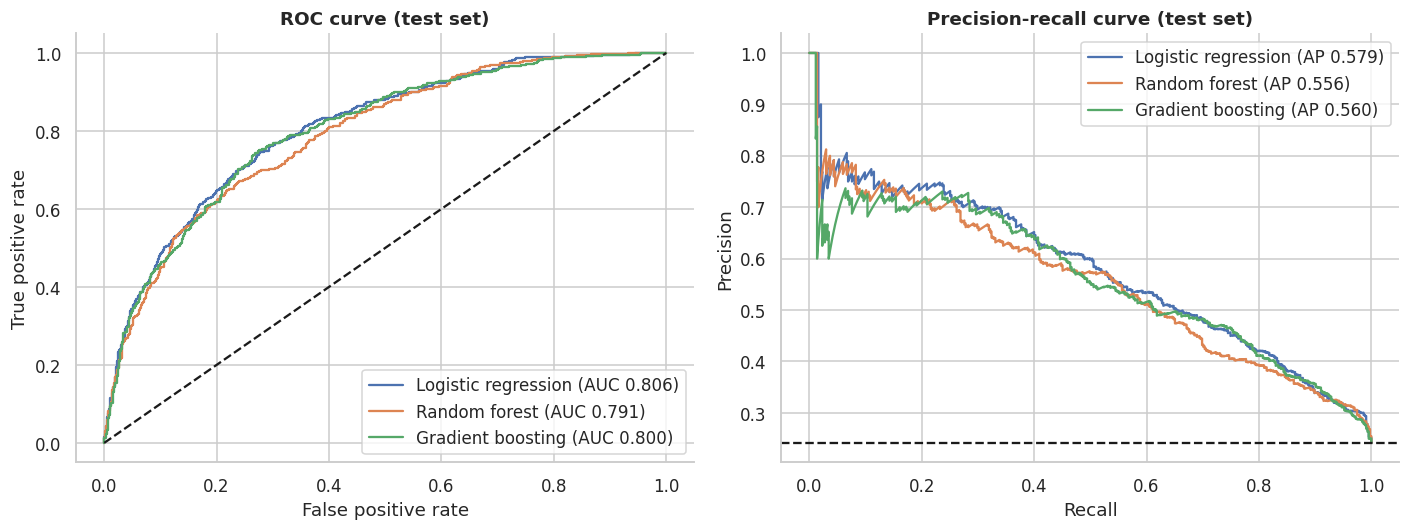

In [13]:
fig, ax = plt.subplots(1,2, figsize=(13,5))
for k,m in fitted.items():
    p = m.predict_proba(Xte)[:,1]; f,t,_ = roc_curve(yte,p); ax[0].plot(f,t,label=f"{k} (AUC {roc_auc_score(yte,p):.3f})")
    pr,rc,_ = precision_recall_curve(yte,p); ax[1].plot(rc,pr,label=f"{k} (AP {average_precision_score(yte,p):.3f})")
ax[0].plot([0,1],[0,1],"k--"); ax[0].set_title("ROC curve (test set)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].axhline(yte.mean(), color="k", ls="--"); ax[1].set_title("Precision-recall curve (test set)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); save("04_roc_pr_curves"); plt.show()

## 7. Interpreting the model - why do customers leave?
Two views: (1) **odds ratios** from the logistic regression (direction + size of effect, per +1 standard deviation for numeric features), (2) **permutation importance** on the test set for the best model (how much does performance drop if a feature is shuffled - model-agnostic).

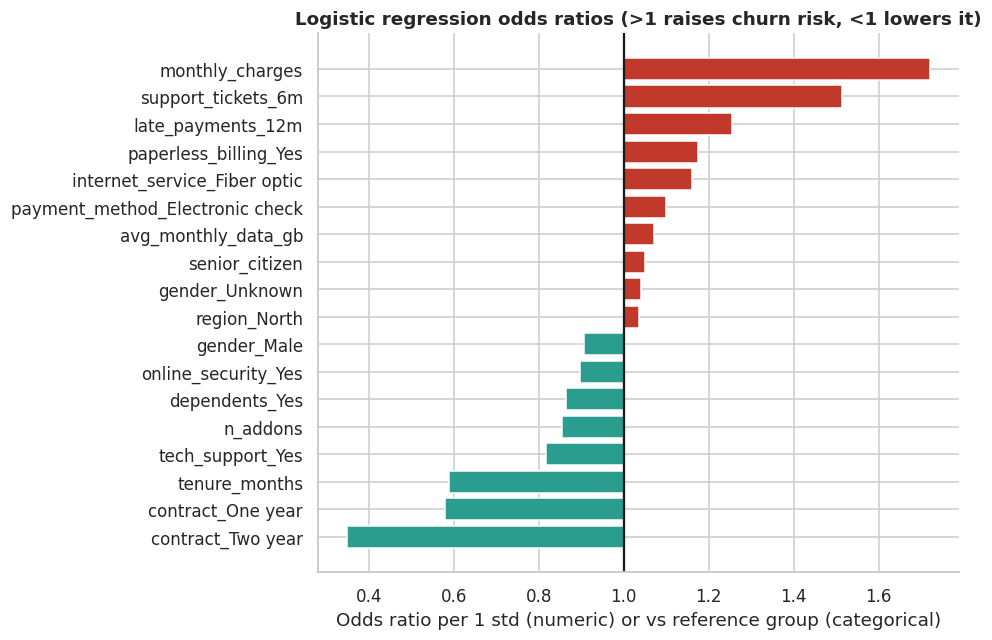

In [14]:
lr = fitted["Logistic regression"]; coef = pd.Series(lr[-1].coef_[0], index=Xd.columns)
odds = np.exp(coef).sort_values(); top = pd.concat([odds.head(8), odds.tail(10)])
fig, ax = plt.subplots(figsize=(9,6)); ax.barh(top.index, top.values-1, left=1, color=["#2A9D8F" if v<1 else "#C0392B" for v in top.values]); ax.axvline(1, color="k")
ax.set_title("Logistic regression odds ratios (>1 raises churn risk, <1 lowers it)"); ax.set_xlabel("Odds ratio per 1 std (numeric) or vs reference group (categorical)"); plt.tight_layout(); save("05_odds_ratios"); plt.show()

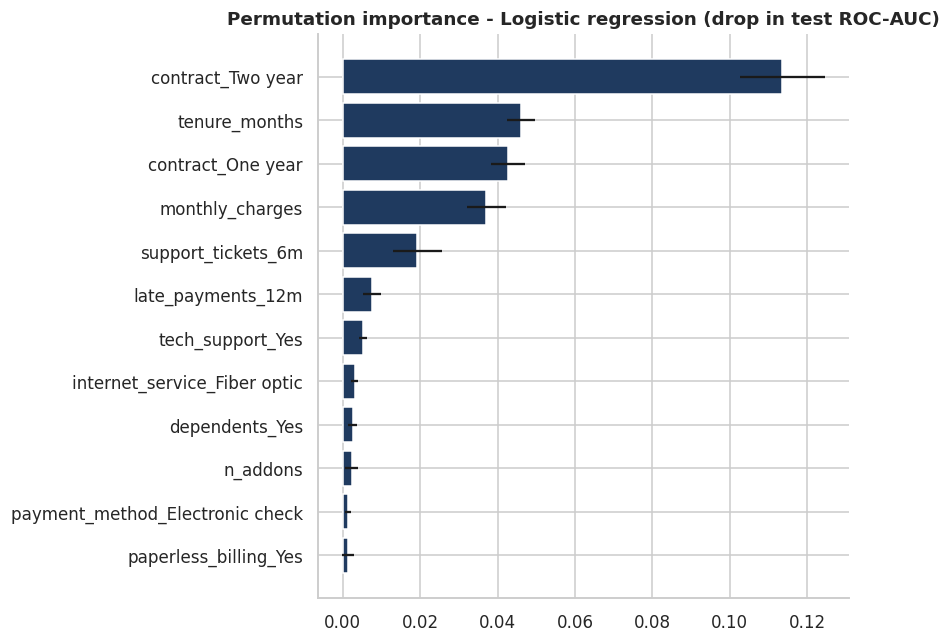

,feature,importance,std
18,contract_Two year,0.1136,0.0110
1,tenure_months,0.0462,0.0036
17,contract_One year,0.0427,0.0044
2,monthly_charges,0.0371,0.0051
4,support_tickets_6m,0.0193,0.0063
5,late_payments_12m,0.0075,0.0024
33,tech_support_Yes,0.0052,0.0010
24,internet_service_Fiber optic,0.0031,0.0008
13,dependents_Yes,0.0025,0.0011
6,n_addons,0.0023,0.0016


In [15]:
bm = fitted[best]; pi = permutation_importance(bm, Xte, yte, scoring="roc_auc", n_repeats=8, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature":Xd.columns, "importance":pi.importances_mean, "std":pi.importances_std}).sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(8,6)); t = imp.head(12).iloc[::-1]; ax.barh(t.feature, t.importance, xerr=t["std"], color="#1F3A5F"); ax.set_title(f"Permutation importance - {best} (drop in test ROC-AUC)"); plt.tight_layout(); save("06_feature_importance"); plt.show()
imp.head(10).round(4)

## 8. From prediction to business decision: who should we call?
A model score alone does not decide anything. Contacting every customer is too expensive; contacting too few leaves money on the table. We choose the **score threshold that maximises expected profit** using explicit, adjustable assumptions:

| Assumption | Value | Meaning |
|---|---|---|
| Cost per retention contact/offer | INR 400 | agent time + discount |
| Offer success rate | 30% | share of would-be churners who stay when contacted |
| Value of a saved customer | 12 months x monthly charge x 40% margin | 1-year contribution |

Expected profit at a threshold = (successes among contacted churners x value) - (contacts x cost). Evaluated on the **test set**.

Best threshold 0.43: contact 364 of 1800 customers (20%), reach 218 churners (recall 50%, precision 60%), expected profit INR 128,009
Contact EVERYONE instead: profit INR -82,782


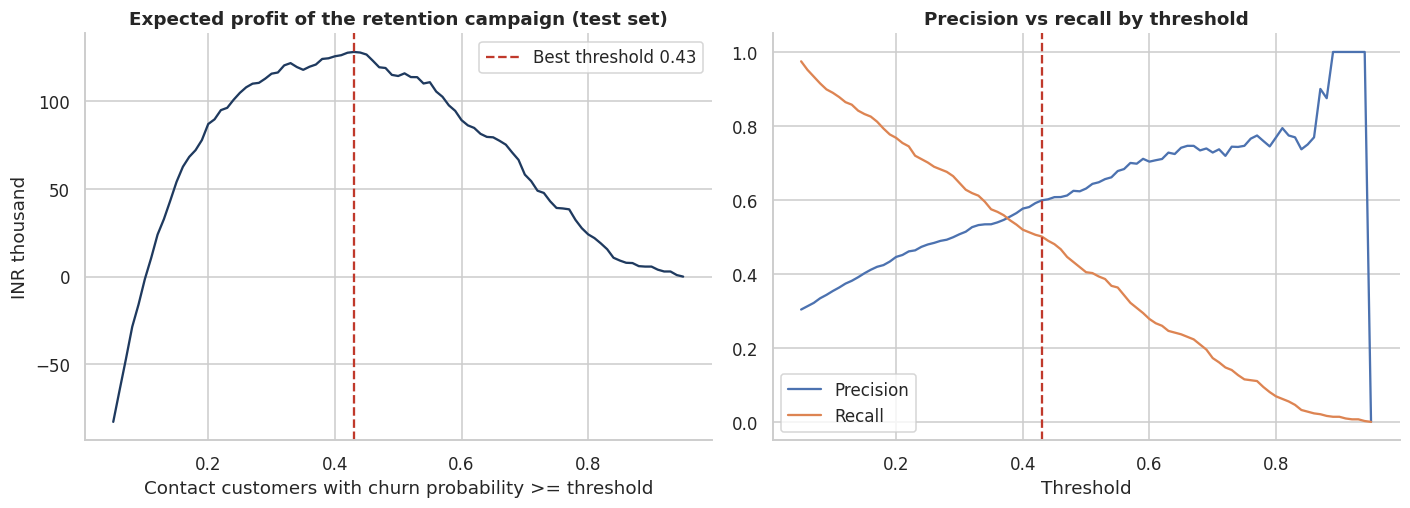

In [16]:
COST, SUCCESS, MARGIN = 400, .30, .40
pt = bm.predict_proba(Xte)[:,1]; te = df.loc[Xte.index].copy(); te["p"] = pt; te["value"] = te.monthly_charges*12*MARGIN
rows=[]
for t in np.arange(.05,.96,.01):
    c = te[te.p>=t]; tp = c.churn_flag.sum()
    rows.append((t, len(c), tp, tp/max(len(c),1), tp/te.churn_flag.sum(), (c.loc[c.churn_flag==1,"value"].sum()*SUCCESS) - COST*len(c)))
curve = pd.DataFrame(rows, columns=["threshold","contacted","true_churners_reached","precision","recall","expected_profit"])
opt = curve.loc[curve.expected_profit.idxmax()]
fig, ax = plt.subplots(1,2, figsize=(13,4.8))
ax[0].plot(curve.threshold, curve.expected_profit/1e3, color="#1F3A5F"); ax[0].axvline(opt.threshold, color="#C0392B", ls="--", label=f"Best threshold {opt.threshold:.2f}"); ax[0].set_title("Expected profit of the retention campaign (test set)"); ax[0].set_xlabel("Contact customers with churn probability >= threshold"); ax[0].set_ylabel("INR thousand"); ax[0].legend()
ax[1].plot(curve.threshold, curve.precision, label="Precision"); ax[1].plot(curve.threshold, curve.recall, label="Recall"); ax[1].axvline(opt.threshold, color="#C0392B", ls="--"); ax[1].set_title("Precision vs recall by threshold"); ax[1].legend(); ax[1].set_xlabel("Threshold")
plt.tight_layout(); save("07_threshold_profit"); plt.show()
print(f"Best threshold {opt.threshold:.2f}: contact {int(opt.contacted)} of {len(te)} customers ({opt.contacted/len(te):.0%}), reach {int(opt.true_churners_reached)} churners (recall {opt.recall:.0%}, precision {opt.precision:.0%}), expected profit INR {opt.expected_profit:,.0f}")
print(f"Contact EVERYONE instead: profit INR {curve.iloc[0].expected_profit:,.0f}")

              Pred stay  Pred churn
Actual stay        1219         146
Actual churn        217         218
              precision    recall  f1-score   support

        Stay      0.849     0.893     0.870      1365
       Churn      0.599     0.501     0.546       435

    accuracy                          0.798      1800
   macro avg      0.724     0.697     0.708      1800
weighted avg      0.788     0.798     0.792      1800



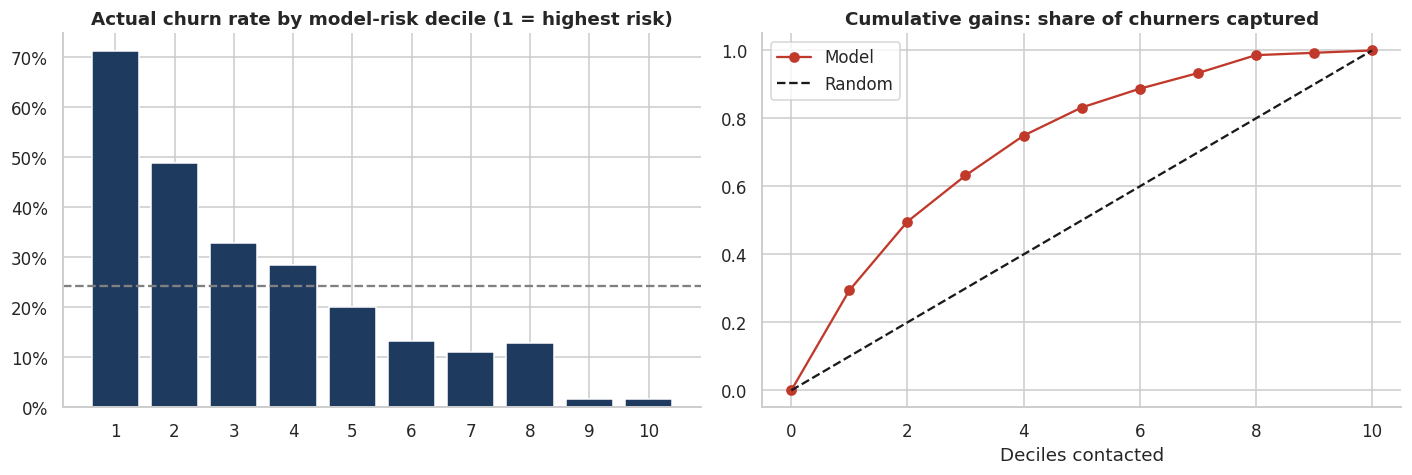

,customers,churners,churn_rate,lift,cum_capture
decile,,,,,
1,180,128,0.711,2.943,0.294
2,180,88,0.489,2.023,0.497
3,180,59,0.328,1.356,0.632
4,180,51,0.283,1.172,0.749
5,180,36,0.200,0.828,0.832
6,180,24,0.133,0.552,0.887
7,180,20,0.111,0.460,0.933
8,180,23,0.128,0.529,0.986
9,180,3,0.017,0.069,0.993


In [17]:
THR = float(opt.threshold)
pred = (pt>=THR).astype(int); cm = confusion_matrix(yte, pred)
print(pd.DataFrame(cm, index=["Actual stay","Actual churn"], columns=["Pred stay","Pred churn"]))
print(classification_report(yte, pred, target_names=["Stay","Churn"], digits=3))
# decile lift / gains
te["decile"] = pd.qcut(te.p.rank(method="first", ascending=False), 10, labels=range(1,11))
lift = te.groupby("decile", observed=True).agg(customers=("p","size"), churners=("churn_flag","sum")).assign(churn_rate=lambda d:d.churners/d.customers)
lift["lift"] = lift.churn_rate/te.churn_flag.mean(); lift["cum_capture"] = lift.churners.cumsum()/te.churn_flag.sum()
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
ax[0].bar(lift.index.astype(str), lift.churn_rate, color="#1F3A5F"); ax[0].axhline(te.churn_flag.mean(), color="grey", ls="--"); ax[0].set_title("Actual churn rate by model-risk decile (1 = highest risk)"); ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"{v:.0%}"))
ax[1].plot([0]+list(range(1,11)), [0]+list(lift.cum_capture), marker="o", color="#C0392B", label="Model"); ax[1].plot([0,10],[0,1], "k--", label="Random"); ax[1].set_title("Cumulative gains: share of churners captured"); ax[1].set_xlabel("Deciles contacted"); ax[1].legend()
plt.tight_layout(); save("08_lift_gains"); plt.show(); lift.round(3)

## 9. Score every customer and build the action list
Out-of-fold predictions (`cross_val_predict`) give every customer a churn probability from a model that **never saw that customer's label** - important, otherwise scores for training customers would be over-optimistic. Customers who have already churned are used for learning; the **action list** is the *active* customers with a high score.

In [18]:
from sklearn.base import clone
oof = cross_val_predict(clone(models[best]), Xd, y, cv=skf, method="predict_proba")[:,1]
sc = df.copy(); sc["churn_probability"] = oof
crit = min(THR+.20, .90)
sc["risk_tier"] = np.select([sc.churn_probability>=crit, sc.churn_probability>=THR, sc.churn_probability>=THR*.6], ["Critical","High","Medium"], default="Low")
sc["risk_tier"] = pd.Categorical(sc.risk_tier, ["Low","Medium","High","Critical"])
sc["annual_value_inr"] = (sc.monthly_charges*12*MARGIN).round(0)
active = sc[sc.churn_flag==0]
act = active.groupby("risk_tier", observed=True).agg(customers=("customer_id","size"), monthly_revenue=("monthly_charges","sum"), avg_prob=("churn_probability","mean")).assign(share=lambda d:d.customers/d.customers.sum())
print(f"Out-of-fold ROC-AUC (all customers): {roc_auc_score(y, oof):.3f}")
act.round(3)

Out-of-fold ROC-AUC (all customers): 0.818


,customers,monthly_revenue,avg_prob,share
risk_tier,,,,
Low,4100,2569332.0,0.094,0.751
Medium,743,536659.0,0.335,0.136
High,443,355353.0,0.517,0.081
Critical,173,155986.0,0.705,0.032


In [19]:
hr = active[active.churn_probability>=THR]
print(f"Active customers at/above threshold {THR:.2f}: {len(hr):,} of {len(active):,} ({len(hr)/len(active):.0%}) | monthly revenue at risk INR {hr.monthly_charges.sum():,.0f} (annualised INR {hr.monthly_charges.sum()*12/1e6:.2f} M)")
print("Profile of the high-risk active group:"); print(hr.contract.value_counts(normalize=True).round(2).to_dict()); print(hr.internet_service.value_counts(normalize=True).round(2).to_dict())
hr.sort_values("churn_probability", ascending=False)[["customer_id","region","contract","internet_service","tenure_months","monthly_charges","support_tickets_6m","churn_probability"]].head(10).round(3)

Active customers at/above threshold 0.43: 616 of 5,459 (11%) | monthly revenue at risk INR 511,339 (annualised INR 6.14 M)
Profile of the high-risk active group:
{'Month-to-month': 0.91, 'One year': 0.08, 'Two year': 0.01}
{'Fiber optic': 0.71, 'DSL': 0.25, 'No internet': 0.04}


,customer_id,region,contract,internet_service,tenure_months,monthly_charges,support_tickets_6m,churn_probability
3226,CUST102188,West,Month-to-month,Fiber optic,7,983.0,4,0.886
4455,CUST106458,North,Month-to-month,Fiber optic,6,1023.0,4,0.877
6972,CUST105205,North,Month-to-month,Fiber optic,5,970.0,3,0.873
6091,CUST101644,South,Month-to-month,Fiber optic,5,784.0,4,0.847
2150,CUST101328,South,Month-to-month,DSL,1,711.0,5,0.845
4758,CUST106230,North,Month-to-month,Fiber optic,5,880.0,1,0.834
262,CUST102711,North,Month-to-month,Fiber optic,42,876.0,5,0.831
5028,CUST105324,West,Month-to-month,Fiber optic,25,911.0,4,0.829
3175,CUST101592,East,Month-to-month,Fiber optic,27,865.0,4,0.829
5251,CUST104544,East,Month-to-month,Fiber optic,36,1048.0,4,0.826


## 10. Retention playbook - match the offer to the reason
Segments are rule-based on the high-risk group so each has a clear, explainable action.

In [20]:
def playbook(r):
    if r.contract=="Month-to-month" and r.tenure_months>12: return "Loyal but uncommitted: offer 12-month contract with price lock"
    if r.contract=="Month-to-month" and r.tenure_months<=12: return "New & flexible: onboarding call + first-year contract discount"
    if r.support_tickets_6m>=3: return "Service pain: proactive technical visit / priority support"
    if r.tech_support=="No" and r.internet_service!="No internet": return "Unprotected: free 3-month tech-support trial"
    if r.payment_method=="Electronic check": return "Payment friction: move to auto-pay with small bill credit"
    return "General: loyalty reward / satisfaction call"
hr = hr.copy(); hr["playbook"] = hr.apply(playbook, axis=1)
pb = hr.groupby("playbook").agg(customers=("customer_id","size"), avg_prob=("churn_probability","mean"), monthly_revenue=("monthly_charges","sum")).sort_values("customers", ascending=False); pb["share"]=pb.customers/pb.customers.sum()
pb.round(3)

,customers,avg_prob,monthly_revenue,share
playbook,,,,
Loyal but uncommitted: offer 12-month contract with price lock,379,0.563,322113.0,0.615
New & flexible: onboarding call + first-year contract discount,180,0.602,136306.0,0.292
Service pain: proactive technical visit / priority support,31,0.519,28729.0,0.050
Unprotected: free 3-month tech-support trial,21,0.506,19476.0,0.034
Payment friction: move to auto-pay with small bill credit,4,0.471,3646.0,0.006
General: loyalty reward / satisfaction call,1,0.432,1069.0,0.002


In [21]:
# Expected campaign result on the whole active high-risk group (same assumptions as section 8; probabilities are used as expected values; check calibration below)
exp_churners = hr.churn_probability.sum(); saved = exp_churners*SUCCESS; value = (hr.churn_probability*hr.annual_value_inr).sum()*SUCCESS
print(f"Contacts: {len(hr):,} | cost INR {len(hr)*COST:,.0f} | expected churners among them ~{exp_churners:,.0f} | expected saved ~{saved:,.0f}")
print(f"Expected 1-year contribution protected INR {value:,.0f} -> net benefit INR {value-len(hr)*COST:,.0f} | ROI {(value-len(hr)*COST)/(len(hr)*COST):.1f}x  (assumption-driven: success rate 30%)")

Contacts: 616 | cost INR 246,400 | expected churners among them ~351 | expected saved ~105
Expected 1-year contribution protected INR 423,476 -> net benefit INR 177,076 | ROI 0.7x  (assumption-driven: success rate 30%)


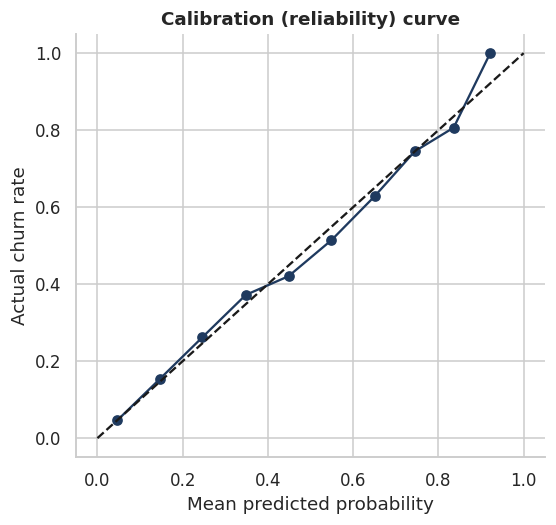

,n,predicted,actual
bin,,,
"(0.0, 0.1]",2624,0.047,0.046
"(0.1, 0.2]",1370,0.147,0.155
"(0.2, 0.3]",919,0.246,0.262
"(0.3, 0.4]",629,0.348,0.372
"(0.4, 0.5]",516,0.448,0.421
"(0.5, 0.6]",455,0.549,0.514
"(0.6, 0.7]",347,0.650,0.628
"(0.7, 0.8]",231,0.744,0.745
"(0.8, 0.9]",93,0.836,0.806


In [22]:
# Calibration check: do predicted probabilities match actual churn rates?  (out-of-fold, all customers)
cal = sc.assign(bin=pd.cut(sc.churn_probability, [0,.1,.2,.3,.4,.5,.6,.7,.8,.9,1.0])).groupby("bin", observed=True).agg(n=("churn_flag","size"), predicted=("churn_probability","mean"), actual=("churn_flag","mean"))
fig, ax = plt.subplots(figsize=(5.5,5)); ax.plot(cal.predicted, cal.actual, marker="o", color="#1F3A5F"); ax.plot([0,1],[0,1],"k--"); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Actual churn rate"); ax.set_title("Calibration (reliability) curve"); save("09_calibration"); plt.show()
cal.round(3)

## 11. Export tables for SQL and Power BI

In [23]:
out = sc.drop(columns=["churn_flag"]).copy(); out["churn_probability"]=out.churn_probability.round(4); out["signup_month"]=out.signup_date.dt.strftime("%Y-%m"); out["signup_date"]=out.signup_date.dt.strftime("%Y-%m-%d")
out["tenure_band"]=out.tenure_band.astype(str); out["charge_band"]=out.charge_band.astype(str); out["risk_tier"]=out.risk_tier.astype(str)
out["is_churned"]=(out.churn=="Yes").astype(int); out["n_addons"]=X.n_addons.values
out = out.merge(hr[["customer_id","playbook"]], on="customer_id", how="left"); out["playbook"]=out.playbook.fillna("")
out.to_csv(f"{PBI}/fact_customers.csv", index=False); out.to_csv(f"{DATA}/telecom_churn_scored.csv", index=False)
imp.round(5).to_csv(f"{PBI}/fact_feature_importance.csv", index=False); curve.round(4).to_csv(f"{PBI}/fact_threshold_curve.csv", index=False); lift.reset_index().round(4).to_csv(f"{PBI}/fact_lift_deciles.csv", index=False)
pd.concat([cv_df, test_res], axis=1).reset_index().rename(columns={"index":"model"}).to_csv(f"{PBI}/fact_model_comparison.csv", index=False)
drivers.round(4).to_csv(f"{PBI}/fact_churn_drivers.csv", index=False)
print({f:os.path.getsize(f"{PBI}/{f}")//1024 for f in sorted(os.listdir(PBI))}, "KB")

{'fact_churn_drivers.csv': 0, 'fact_customers.csv': 1524, 'fact_feature_importance.csv': 1, 'fact_lift_deciles.csv': 0, 'fact_model_comparison.csv': 0, 'fact_threshold_curve.csv': 3} KB


## 12. Key findings (generated from the results)

In [24]:
cm_rate = df.groupby("contract").churn_flag.mean()
tops = drivers.head(3).factor.tolist()
find = [
 f"1. Overall churn {rate:.1%} ({df.churn_flag.sum():,} of {len(df):,}); churned customers carried INR {lost_mrr*12/1e6:.1f} M of annualised revenue ({lost_mrr/tot_mrr:.0%} of monthly revenue).",
 f"2. Contract is the strongest driver: month-to-month churn {cm_rate['Month-to-month']:.0%} vs one-year {cm_rate['One year']:.0%} and two-year {cm_rate['Two year']:.0%}.",
 f"3. Month-to-month + Fiber optic customers are {len(hi)/len(df):.0%} of the base but {hi.churn_flag.sum()/df.churn_flag.sum():.0%} of churners (churn rate {hi.churn_flag.mean():.0%}).",
 f"4. New customers (0-6 months) churn at {df[df.tenure_band=='0-6 m'].churn_flag.mean():.0%} vs {df[df.tenure_band=='49+ m'].churn_flag.mean():.0%} for 49+ months; customers with 3+ support tickets churn at {df[df.support_tickets_6m>=3].churn_flag.mean():.0%} vs {df[df.support_tickets_6m==0].churn_flag.mean():.0%} with none.",
 f"5. Best model: {best} - test ROC-AUC {test_res.loc[best,'test_roc_auc']:.3f}, PR-AUC {test_res.loc[best,'test_pr_auc']:.3f} (random PR-AUC {yte.mean():.2f}); logistic baseline {test_res.loc['Logistic regression','test_roc_auc']:.3f}.",
 f"6. Top decile of risk contains {lift.loc[1,'churn_rate']:.0%} churners (lift {lift.loc[1,'lift']:.1f}x); top 3 deciles capture {lift.loc[3,'cum_capture']:.0%} of churners.",
 f"7. Profit-optimal threshold {THR:.2f}: contact {opt.contacted/len(te):.0%} of customers, recall {opt.recall:.0%}, precision {opt.precision:.0%}; expected profit INR {opt.expected_profit:,.0f} vs INR {curve.iloc[0].expected_profit:,.0f} if everyone is contacted.",
 f"8. {len(hr):,} active customers are above the threshold, with INR {hr.monthly_charges.sum()*12/1e6:.2f} M annualised revenue at risk; expected net benefit of the campaign INR {value-len(hr)*COST:,.0f}.",
]
print("\n".join(find)); json.dump(find, open("../docs/key_findings.json","w"), indent=1)

1. Overall churn 24.2% (1,741 of 7,200); churned customers carried INR 16.3 M of annualised revenue (27% of monthly revenue).
2. Contract is the strongest driver: month-to-month churn 41% vs one-year 16% and two-year 8%.
3. Month-to-month + Fiber optic customers are 18% of the base but 43% of churners (churn rate 56%).
4. New customers (0-6 months) churn at 44% vs 12% for 49+ months; customers with 3+ support tickets churn at 41% vs 15% with none.
5. Best model: Logistic regression - test ROC-AUC 0.806, PR-AUC 0.579 (random PR-AUC 0.24); logistic baseline 0.806.
6. Top decile of risk contains 71% churners (lift 2.9x); top 3 deciles capture 63% of churners.
7. Profit-optimal threshold 0.43: contact 20% of customers, recall 50%, precision 60%; expected profit INR 128,009 vs INR -82,782 if everyone is contacted.
8. 616 active customers are above the threshold, with INR 6.14 M annualised revenue at risk; expected net benefit of the campaign INR 177,076.
